# Predicting New-User Engagement on Zindi
### Do time-series foundation models (TimesFM-3) help? A pre-registered proof of concept

**Repository:** `zindi-engagement-timesfm` · Data: Zindi New User Engagement Prediction Challenge (not redistributed)

**Contents:** 1 Problem · 2 Data loading, X and y · 3 Preparation · 4 Exploratory analysis (Seaborn) ·
5 Cross-validation, metric, model and hyper-parameters · 6 Results · 7 Impact and conclusion

## 1. The problem and why it matters

[Zindi](https://zindi.africa) is Africa's largest data-science competition platform. Like most platforms,
it loses most new users quickly: **only 11–20% of people who sign up in a month are active the next month.**

**Task:** for each new user, predict from their first (signup) month whether they will be **active in the
following month** (binary classification).

**Why it matters.** Acquiring a user is far more expensive than keeping one. If the platform knows *which*
new users are likely to return (and which are about to drop), it can:
- target onboarding help, reminders or competition recommendations at the users most worth contacting,
  instead of emailing everyone (lower cost, less spam);
- learn *what behaviour* in the first month predicts retention, which in turn informs product design.

**Research question of this project.** Time-series foundation models (Google's TimesFM-3, 2026) produce
general-purpose representations of time series. Do embeddings of each user's first-month activity curves
add predictive signal beyond carefully engineered features? (Hypotheses H1–H3 were pre-registered.)

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
from pathlib import Path
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
sns.set_theme(style="whitegrid", context="notebook", palette=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
RAW = Path("../data/raw"); RES = Path("../results")
pd.set_option("display.width", 160, "display.max_columns", 20)

## 2. Loading the data with pandas and building X and y

The challenge provides 10 CSV files. Masked IDs; months are encoded (e.g. month 11 precedes month 1).

In [2]:
tables = {f.stem: pd.read_csv(f, low_memory=False) for f in sorted(RAW.glob("*.csv"))}
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in tables.items()}).T

,rows,columns
Blogs,117,6
Comments,467,6
Competition,247,20
CompetitionPartipation,8385,8
Discussion,1439,9
Jobs,34,7
SampleSubmission,1340,2
UserActivity,317292,6
Users,12413,8
VariableDefinitions,61,2


In [3]:
users = tables["Users"]
activity = tables["UserActivity"]
print(users.head(3).to_string(index=False)); print()
print(activity.head(3).to_string(index=False))

 FeatureX  FeatureY     User_ID Countries_ID Created At time  Created At Year  Created At Month  Created At Day_of_month
        0         0 ID_DC6S4E9O         X9GR 19:33:13.663391                1                 1                       16
        1         0 ID_E8S97OUT         X9GR 22:18:18.228921                1                12                       27
        0         0 ID_QZ1HASL3         X9GR 23:13:03.266635                1                 1                        1

    User_ID        Title datetime time  datetime Year  datetime Month  datetime Day_of_month
ID_RT43AK77 comp_ID_IV5D      22:00:38              1              11                     22
ID_RT43AK77 comp_ID_IV5D      00:41:02              1              11                     23
ID_RT43AK77 comp_ID_IV5D      00:53:15              1              11                     23


The raw tables are event logs, not a model-ready table. Our pipeline (`src/`) turns them into **one row per
new user**: the inputs **X** are built only from events in the user's signup month, and the target **y** is
whether the user has activity in the following month. Below we build X and y with that pipeline.

In [4]:
from src.io import load_config, load_users, load_events
from src.batch_events import detect_batch_events
from src.labels import build_labels, feature_window
from src.features import build_features
from src.features_v2 import build_features_v2

cfg = load_config("../configs/default.yaml"); cfg["data_dir"] = str(RAW)
all_users = load_users(cfg)                    # users + signup cohort (month index)
events = load_events(cfg)                      # all event tables on one corrected time axis
batches = detect_batch_events(events, cfg)     # system-wide batch events (see section 3)
labelled = build_labels(all_users, events, batches, cfg)          # cohorts with an observed next month
labelled["never_tracked"] = ~labelled.uid.isin(set(events.uid))
window = feature_window(events, labelled, batches, cfg)           # signup-month events only

X = (build_features(labelled, window, cfg)
     .join(build_features_v2(labelled, window, events, cfg).drop(columns=["platform_live_comps"]))
     .loc[labelled.uid])
y = labelled.set_index("uid").label_engaged.loc[X.index]
print("X:", X.shape, "   y:", y.shape, "   positive rate:", round(y.mean(), 3))
X.iloc[:3, :8]

X: (9026, 68)    y: (9026,)    positive rate: 0.187


,signup_day,days_observed,browse_count,browse_active_days,browse_recency,browse_span,browse_last7,browse_rate
uid,,,,,,,,
ID_DC6S4E9O,15.814741,14.185259,2.0,1.0,14.181412,0.003843,0.0,0.140991
ID_E8S97OUT,26.929378,4.070622,11.0,2.0,2.589352,1.481273,11.0,2.702289
ID_QZ1HASL3,0.967399,29.032601,10.0,1.0,29.029317,0.003275,0.0,0.344440


## 3. Preparing the dataset (each step motivated)

| Step | What we did | Why |
|---|---|---|
| Month order | Ordered the masked month codes as 11, 12, 1, …, 5 | Tested all 5,040 orders: only this one leaves ~0% of events before signup (0.071%) |
| Clock alignment | Shifted UserActivity by −2 h, then −1 h after a detected switch | Its clock ran ahead of the other tables; after the fix 99.94% of "Signed Up" events coincide with signup |
| Real month lengths | 30/31/30/31/31/30 days instead of a 31-day grid | Recency and "last 7 days" features must use the true month end |
| **Target** | `y = 1` if the user has any activity next month, **excluding badge events** | A one-day system batch awarded a badge to 2,892 users; counting it made 77% of one cohort "active" (true rate 27%) |
| Feature window | Only signup-month events; nothing from the target month | Prevents leakage: the model sees exactly what is known at prediction time |
| Duplicates | Dropped "Joined Competition" activity rows | 98.75% duplicate a row of the participation table |
| Missing values | `Countries_ID` missing for 3,507 users → its own category `"missing"` | Missingness is informative (untracked/incomplete profiles); dropping would lose 28% of users |
| Categorical encoding | Country/FeatureX/FeatureY kept as categories (CatBoost native, levels from training data only) | 123 countries: one-hot would be sparse; native handling avoids leakage of unseen levels |
| Feature generation | Per behaviour group (browse, learn, compete, contribute, account, onboarding, badges, comments): count, active days, recency, span, last-7-day count, rate; plus sessions, activity trend, **last-active position**, **competition liveness** | Engagement theory: *how recently*, *how regularly* and *in what context* a user acts predicts return (motivated by EDA below) |
| Skewed counts | `log1p` for linear models only | Counts are heavy-tailed (browse_count up to 469, mean 6.8); trees do not need it |

In [5]:
print("Confirmed batch events removed:\n", batches[batches.confirmed][["etype","users","window_share","solo_share"]].to_string(index=False))
cohort_rates = labelled.groupby("cohort")[["label_any", "label_engaged"]].mean().round(3)
cohort_rates

Confirmed batch events removed:
      etype  users  window_share  solo_share
badge_OCZE   2892         0.993       0.944


,label_any,label_engaged
cohort,,
0,0.184,0.184
1,0.772,0.272
2,0.199,0.198
3,0.169,0.169
4,0.114,0.114


## 4. Exploratory analysis (Seaborn)

We look for patterns that make the task more specific and guide model choice.

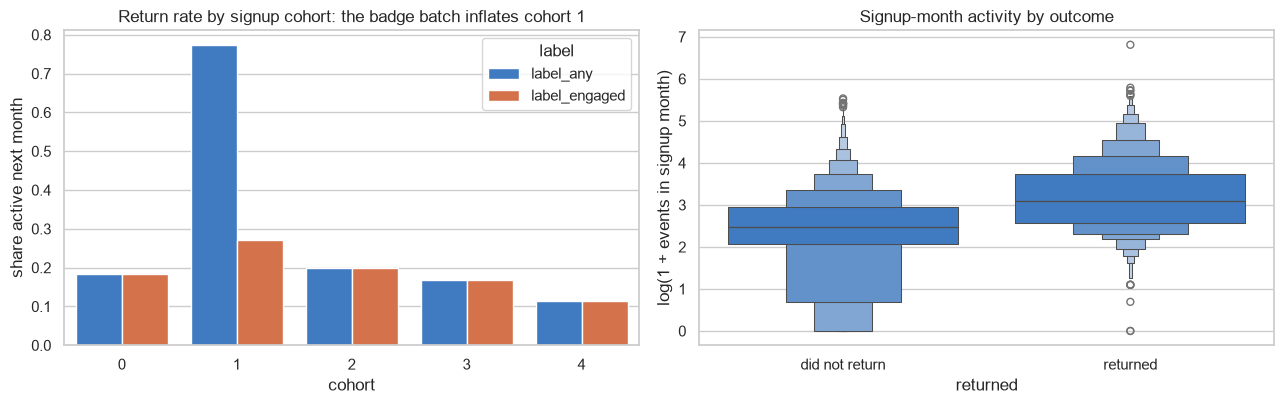

In [6]:
d = X.assign(returned=y.values, cohort=labelled.set_index("uid").cohort.loc[X.index].values)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
cr = labelled.melt(id_vars="cohort", value_vars=["label_any", "label_engaged"], var_name="label", value_name="rate")
sns.barplot(data=cr, x="cohort", y="rate", hue="label", errorbar=None, ax=ax[0])
ax[0].set_title("Return rate by signup cohort: the badge batch inflates cohort 1"); ax[0].set_ylabel("share active next month")
sns.boxenplot(data=d, x="returned", y=np.log1p(d.total_events), ax=ax[1])
ax[1].set_title("Signup-month activity by outcome"); ax[1].set_ylabel("log(1 + events in signup month)"); ax[1].set_xticklabels(["did not return", "returned"])
plt.tight_layout(); plt.savefig(FIG / "eda_cohorts_activity.png", dpi=150); plt.show()

**Findings.** (1) The official label is distorted in cohort 1 by a batch badge award → we redefine the target
(section 3). (2) Return rates drift across cohorts (0.20 → 0.17 → 0.11): **a random split would leak the
future and overstate quality**, so we use time-based validation (section 5). (3) Returners are more active,
but the distributions overlap heavily: activity alone cannot separate them.

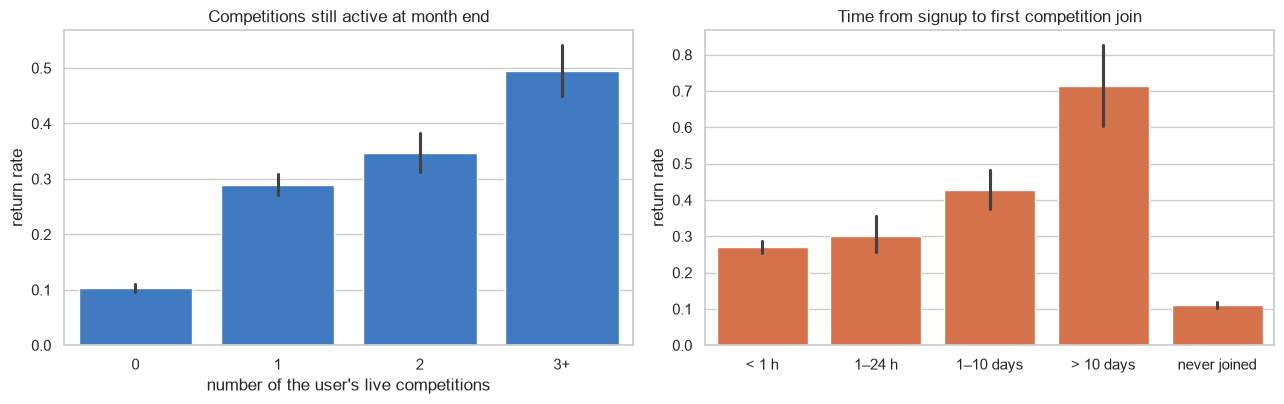

In [7]:
first_join_h = (window[window.source == "participation"].groupby("uid").t_day.min()
                - labelled.set_index("uid").signup_t_day) * 24
bins = pd.cut(first_join_h.reindex(X.index), [-1, 1, 24, 240, 1e6], labels=["< 1 h", "1–24 h", "1–10 days", "> 10 days"])
d["first_join"] = bins.cat.add_categories("never joined").fillna("never joined")
d["live_comps"] = d.n_live_comps.clip(0, 3).astype(int).astype(str).replace({"3": "3+"})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(data=d, x="live_comps", y="returned", order=["0", "1", "2", "3+"], errorbar=("ci", 95), ax=ax[0], color="#2a78d6")
ax[0].set_title("Competitions still active at month end"); ax[0].set_ylabel("return rate"); ax[0].set_xlabel("number of the user's live competitions")
sns.barplot(data=d, x="first_join", y="returned", order=["< 1 h", "1–24 h", "1–10 days", "> 10 days", "never joined"], errorbar=("ci", 95), ax=ax[1], color="#eb6834")
ax[1].set_title("Time from signup to first competition join"); ax[1].set_ylabel("return rate"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "eda_competitions.png", dpi=150); plt.show()

**Findings.** Competition context is the strongest signal we found. Users with 3+ competitions still running at
month end return far more often than users with none, and users who come back **days later** to join a
competition are the most committed (a join in the first session is often a one-off hackathon visit).
→ We engineered *competition liveness* and *last-active position* features from this.

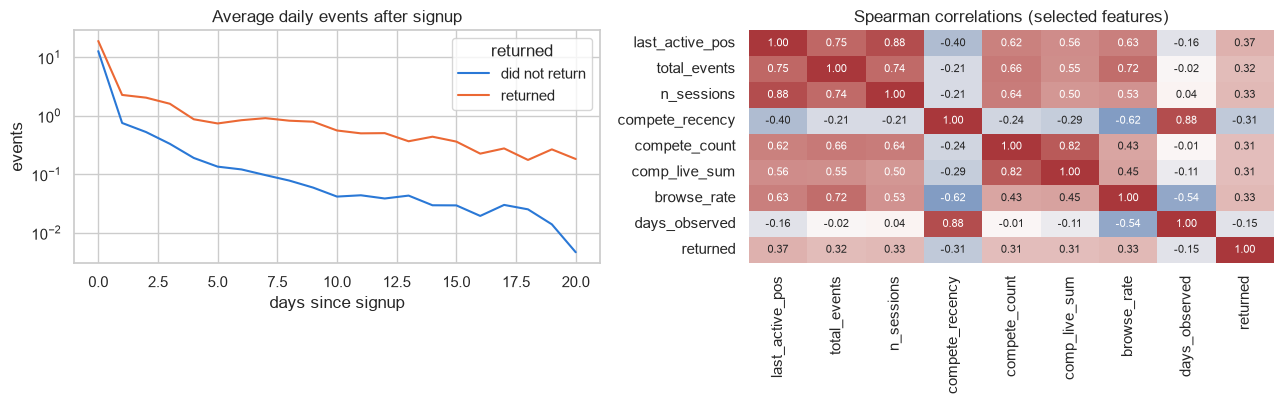

In [8]:
w = window.merge(labelled[["uid", "signup_t_day"]], on="uid")
w["days_since_signup"] = np.floor(w.t_day - w.signup_t_day).clip(0, 30)
daily = (w.groupby(["uid", "days_since_signup"]).size().unstack(fill_value=0)
         .reindex(index=X.index, fill_value=0).stack().rename("events").reset_index())
daily["returned"] = daily.uid.map(y).map({0: "did not return", 1: "returned"})
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.lineplot(data=daily[daily.days_since_signup <= 20], x="days_since_signup", y="events", hue="returned", errorbar=None, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set_title("Average daily events after signup"); ax[0].set_xlabel("days since signup")
top = ["last_active_pos", "total_events", "n_sessions", "compete_recency", "compete_count", "comp_live_sum", "browse_rate", "days_observed"]
sns.heatmap(d[top + ["returned"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1], cbar=False, annot_kws={"size": 8})
ax[1].set_title("Spearman correlations (selected features)")
plt.tight_layout(); plt.savefig(FIG / "eda_daily_corr.png", dpi=150); plt.show()

**Findings.** Almost everyone is active on signup day; returners differ in **coming back on later days**,
which is why recency and last-active position matter more than raw volume. Many features are strongly
correlated (activity volume) → tree ensembles, which handle collinearity and interactions, are a natural
choice; linear models need the `log1p` + scaling above. 9% of users have **no** signup-month events and
almost never return (0.24%): kept as a segment and reported separately.

## 5. Cross-validation, metric, model and hyper-parameters

**Validation (motivated by the cohort drift above): rolling-origin folds by signup month.**
| Fold | Train cohorts | Validation (tuning, early stopping, threshold) | Test |
|---|---|---|---|
| 1 | 0, 1 | 2 | **3** |
| 2 | 0, 1, 2 | 3 | **4** |

No random K-fold: users from the future would leak into training. Every fitted object (scalers, PCA,
category levels, thresholds) sees training data only; `tests/test_no_leakage.py` enforces this.

**Metric.** Classes are imbalanced (11–20% positives), so accuracy is meaningless (predicting "nobody returns"
scores 85%). We report **F1** (the competition metric; threshold tuned on validation), plus **PR-AUC** and
**ROC-AUC** (threshold-free; robust to the drift in base rate). Differences between models are tested with a
**paired bootstrap** (2,000 resamples) and reported with 95% confidence intervals.

**Models.** Baselines: last-7-days rule, logistic regression, random forest, LightGBM (tuned: 30-trial random
search on validation PR-AUC, frozen afterwards), MiniRocket. Proposed: TimesFM-3 embeddings (alone and as PCA
features in LightGBM). Final: **CatBoost** on all engineered features (handles categorical variables natively and
was best on validation), mean of 5 seeds.

In [9]:
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from src.evaluate import make_folds, split, tune_threshold
from src.features import static_cols
cats = static_cols(cfg)
lab = labelled.copy()
rows = []
for fold in [f for f in make_folds(cfg) if f["kind"] == "primary"]:
    tr, va, _ = split(lab, fold)                            # the test cohort is not touched here
    p = np.mean([CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=4, l2_leaf_reg=5, random_seed=s,
                                    verbose=0, od_type="Iter", od_wait=100, cat_features=cats)
                 .fit(X.loc[tr.uid], y.loc[tr.uid], eval_set=(X.loc[va.uid], y.loc[va.uid]), use_best_model=True)
                 .predict_proba(X.loc[va.uid])[:, 1] for s in range(5)], 0)
    yv = y.loc[va.uid].values
    rows.append({"fold": fold["name"], "train cohorts": fold["train"], "val cohort": fold["val"][0],
                 "val PR-AUC": average_precision_score(yv, p), "val ROC-AUC": roc_auc_score(yv, p),
                 "tuned threshold": tune_threshold(yv, p, cfg)})
pd.DataFrame(rows).round(4)

,fold,train cohorts,val cohort,val PR-AUC,val ROC-AUC,tuned threshold
0,test_c3,"[0, 1]",2,0.5657,0.7669,0.36
1,test_c4,"[0, 1, 2]",3,0.5530,0.7973,0.31


In [10]:
search = pd.read_csv(RES / "catboost_tuning_val.csv").sort_values("val_pr", ascending=False)
print("CatBoost random search (14 configurations, validation only) — top 5:")
search.head(5).round(4)

CatBoost random search (14 configurations, validation only) — top 5:


,random_strength,learning_rate,l2_leaf_reg,depth,bagging_temperature,val_pr,val_roc
0,2.0,0.03,3,5,0.0,0.5601,0.7839
1,2.0,0.02,3,6,1.0,0.5581,0.7818
2,2.0,0.02,1,5,0.0,0.5577,0.7810
3,1.0,0.02,3,3,1.0,0.5567,0.7810
4,2.0,0.02,5,3,0.5,0.5566,0.7816


**Hyper-parameters.** LightGBM: 30-trial random search per fold, best settings frozen in the config and reused
for every model built on it. CatBoost: depth 4, learning rate 0.03, L2 5 (a 14-configuration search found nothing
better than 0.560 vs 0.559: a plateau). Shallow trees win across all libraries: the signal is a few strong
effects rather than deep interactions. Development used validation only; the final models were fixed in
`results/overnight_protocol.md` **before** a single test evaluation.

## 6. Results (test cohorts 3 and 4; never used for any choice)

In [11]:
allres = pd.concat([pd.read_csv(RES / f) for f in ["baselines.csv", "proposed.csv", "overnight_final.csv"]])
t = allres[(allres.split == "test") & (allres.population == "all") & (allres.kind == "primary")]
names = {"B0": "Rule: active in last 7 days", "B1": "Logistic regression", "B2": "Random forest",
         "B3": "LightGBM (tuned)", "B4": "MiniRocket (time series)", "P1": "TimesFM embeddings + LR",
         "P4_pca8": "LightGBM + TimesFM (pre-registered hybrid)", "N2": "CatBoost + domain features (best)"}
tab = t[t.model.isin(names)].groupby("model")[["f1", "roc_auc", "pr_auc"]].mean().loc[list(names)]
tab.index = tab.index.map(names); tab.round(3)

,f1,roc_auc,pr_auc
model,,,
Rule: active in last 7 days,0.394,0.691,0.233
Logistic regression,0.453,0.778,0.456
Random forest,0.443,0.774,0.430
LightGBM (tuned),0.446,0.794,0.472
MiniRocket (time series),0.457,0.788,0.467
TimesFM embeddings + LR,0.476,0.808,0.469
LightGBM + TimesFM (pre-registered hybrid),0.459,0.795,0.474
CatBoost + domain features (best),0.482,0.812,0.505


In [12]:
b = pd.concat([pd.read_csv(RES / "bootstrap_overnight.csv"), pd.read_csv(RES / "bootstrap_proposed.csv")])
b = b[(b.scope == "pooled") & (b.population == "all")]
sel = b[((b.a == "N2") & (b.b == "B3")) | ((b.a == "P4_pca8") & (b.b == "B3"))]
sel.assign(**{"95% CI": sel.apply(lambda r: f"[{r.ci_lo:+.3f}, {r.ci_hi:+.3f}]", axis=1)})[["a", "b", "metric", "diff", "95% CI"]].round(3)

,a,b,metric,diff,95% CI
20,N2,B3,f1,0.036,"[+0.018, +0.055]"
23,N2,B3,roc_auc,0.018,"[+0.011, +0.025]"
26,N2,B3,pr_auc,0.033,"[+0.020, +0.045]"
182,P4_pca8,B3,f1,0.013,"[-0.001, +0.027]"
185,P4_pca8,B3,roc_auc,0.001,"[-0.001, +0.004]"
188,P4_pca8,B3,pr_auc,0.002,"[-0.003, +0.008]"


**Hypotheses (pre-registered).** H1 (embeddings alone underperform): *mixed* — raw-count embeddings match the
GBM, smoothed-curve embeddings are significantly worse. H2 (smoothing helps): *reversed*. **H3 (TimesFM hybrid
beats LightGBM): inconclusive** — all three confidence intervals include 0.

**Why TimesFM did not help.** It normalises every series by its own mean and spread, so a series and the same
series ×100 get identical embeddings (cosine 1.000): it discards *how much* a user did, the strongest signal. A
custom multi-view network that may weight its inputs per user put only **5% weight on the TimesFM view**.

**What did help:** domain features + CatBoost: **+0.036 F1, +0.018 ROC-AUC, +0.033 PR-AUC** over tuned LightGBM,
all CIs above zero. About 15 very different methods (kernels, XGBoost, stacking, GRU, TabICLv2 2026 tabular
foundation model, custom networks) all plateau at the same validation PR-AUC (0.53–0.56): the limit is the
information in a new user's first month.

**Context.** The competition leaderboard's top private scores (0.85–0.87) are *not* F1 — a confirmed duplicate-ID
scoring bug and accuracy-based re-scoring; "predict nobody returns" already gives 0.853 accuracy. Honest entries
reached 0.42–0.51 F1; ours (0.48) sits in that band (`results/leaderboard_analysis.md`).

## 7. Impact, applicability and conclusion

In [13]:
rows = []
for fold in ["test_c3", "test_c4"]:
    p = pd.read_parquet(RES / f"cache/preds/N2__{fold}.parquet").query("split == 'test'").sort_values("p", ascending=False)
    base = p.y.mean()
    for k in (0.05, 0.10, 0.20):
        top = p.head(int(len(p) * k))
        rows.append({"contact top": f"{int(k*100)}%", "precision": top.y.mean(), "base rate": base,
                     "lift": top.y.mean() / base, "share of all returners reached": top.y.sum() / p.y.sum()})
lift = pd.DataFrame(rows).groupby("contact top", sort=False).mean().round(3); lift

,precision,base rate,lift,share of all returners reached
contact top,,,,
5%,0.664,0.142,4.688,0.233
10%,0.556,0.142,3.929,0.392
20%,0.424,0.142,3.020,0.604


In [14]:
n_new = 2000                                  # roughly one month of Zindi signups
k = 0.10; contacts = int(n_new * k)
prec, base = lift.loc["10%", "precision"], lift.loc["10%", "base rate"]
print(f"Contacting {contacts} users chosen by the model reaches {contacts*prec:.0f} future-active users;")
print(f"the same budget spent at random reaches {contacts*base:.0f}  ->  {contacts*(prec-base):.0f} more per month ({prec/base:.1f}x).")

Contacting 200 users chosen by the model reaches 111 future-active users;
the same budget spent at random reaches 28  ->  83 more per month (3.9x).


**Does the model solve the problem?** Partly — and the analysis shows why "partly" is the ceiling:
- It **ranks** new users well (ROC-AUC 0.81; the top 10% return at **3.9× the base rate**), which is exactly what a
  retention team needs to prioritise limited outreach (≈ 80 additional reached future-active users per 200 contacts).
- It cannot classify every user with certainty (F1 ≈ 0.48–0.50): half of the users who return looked, in their
  first month, exactly like users who leave. That information is not in the data — no model we tried recovered it.

**Applicability.** Retrain monthly on the latest cohorts (more recent data helped), use the model as a ranking for
targeted engagement, adjust the threshold for the drifting base rate (we tested a drift-aware rule), and monitor
the never-tracked segment separately.

**Conclusion.** For short, sparse engagement logs, a time-series foundation model adds no practical value over
engineered features, because its normalisation discards activity level. Understanding the domain (competition
liveness, join timing, recency) and an honest time-based evaluation delivered the real, statistically supported
improvement.